# Pneumonia Detection from Chest X-rays Using Transfer Learning (DenseNet121)
**Dataset:** Kaggle Chest X-ray Pneumonia  
**Task:** Binary classification (NORMAL vs PNEUMONIA)  
**Model:** Transfer Learning – DenseNet121      
**Metrics:** Accuracy, F1-score, Confusion Matrix  
**Explainability:** Grad-CAM visualization


In [ ]:
# 1 Install & Setup
!pip install -q opendatasets matplotlib seaborn


In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.models import Model
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2) Download Dataset
We use the Kaggle Chest X-ray Pneumonia dataset.


In [ ]:
import opendatasets as od
od.download("https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia")

train_dir = "chest-xray-pneumonia/chest_xray/train"
val_dir   = "chest-xray-pneumonia/chest_xray/val"
test_dir  = "chest-xray-pneumonia/chest_xray/test"


Skipping, found downloaded files in "./chest-xray-pneumonia" (use force=True to force download)


## 3) Image & Training Settings
  
Set batch size and epochs for training.


In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 25


## 4) Data Preprocessing and Augmentation
We normalize pixel values and apply augmentations to the training set.


In [ ]:
# Training augmentation and normalization
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Validation & Test normalization
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Generators
train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',  # Binary labels
    seed=SEED
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


## 5) Build DenseNet121 Model
We create a deep DenseNet121 with multiple convolutional blocks, batch normalization, dropout, and a binary classifier.


In [ ]:
# Input size
IMAGE_SIZE = (224, 224)

# Load pretrained DenseNet121 convolutional base
densenet = DenseNet121(input_shape=IMAGE_SIZE + (3,), weights='imagenet', include_top=False)

# Freeze pretrained layers
for layer in densenet.layers:
    layer.trainable = False

# Custom classifier
x = Flatten()(densenet.output)       # Flatten feature maps
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(1, activation='sigmoid')(x)  # Binary classification

# Build model
model = Model(inputs=densenet.input, outputs=output)
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 19,883,073 (75.85 MB)

 Trainable params: 12,845,569 (49.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

## 6) Callbacks
We use ModelCheckpoint, ReduceLROnPlateau, and EarlyStopping to optimize training.


In [ ]:
os.makedirs("models", exist_ok=True)
model_path = "models/finaldensenet.keras"

callbacks = [
    ModelCheckpoint(model_path, save_best_only=True, monitor='val_loss', verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', patience=2, factor=0.3, min_lr=1e-6, verbose=1),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]


## 7) Train Model
Training the DenseNet121 on the training set and validating on the validation set.


In [ ]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 683ms/step - accuracy: 0.8317 - loss: 4.1487
Epoch 1: val_loss improved from inf to 0.42478, saving model to models/finaldensenet.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 168s 790ms/step - accuracy: 0.8321 - loss: 4.1308 - val_accuracy: 0.8750 - val_loss: 0.4248 - learning_rate: 0.0010
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 619ms/step - accuracy: 0.9353 - loss: 0.1800
Epoch 2: val_loss improved from 0.42478 to 0.34825, saving model to models/finaldensenet.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 662ms/step - accuracy: 0.9353 - loss: 0.1800 - val_accuracy: 0.8125 - val_loss: 0.3483 - learning_rate: 0.0010
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 606ms/step - accuracy: 0.9368 - loss: 0.1730
Epoch 3: val_loss did not improve from 0.34825
163/163 ━━━━━━━━━━━━━━━━━━━━ 100s 608ms/step - accuracy: 0.9368 - loss: 0.1730 - val_accuracy: 0.9375 - val_loss: 0.3936 - learning_rate: 0.0010
Epoch 4/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 613ms/step - accuracy: 0.

## 8) Evaluate Model
We evaluate on the test set and compute accuracy and F1-score.


In [ ]:

# 8 Evaluate Model
model = keras.models.load_model(model_path)

loss, acc = model.evaluate(test_gen)
print(f"Test Loss: {loss:.4f} | Test Accuracy: {acc*100:.2f}%")

y_pred_prob = model.predict(test_gen)
y_pred = (y_pred_prob > 0.5).astype(int).reshape(-1)
y_true = test_gen.classes

f1 = f1_score(y_true, y_pred)
print(f"F1-score: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['NORMAL','PNEUMONIA']))


20/20 ━━━━━━━━━━━━━━━━━━━━ 28s 659ms/step - accuracy: 0.9015 - loss: 0.4839
Test Loss: 0.3123 | Test Accuracy: 92.31%
20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 864ms/step
F1-score: 0.9397

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.93      0.86      0.89       234
   PNEUMONIA       0.92      0.96      0.94       390

    accuracy                           0.92       624
   macro avg       0.92      0.91      0.92       624
weighted avg       0.92      0.92      0.92       624



## 9) Confusion Matrix
Visualizing predictions with a heatmap.


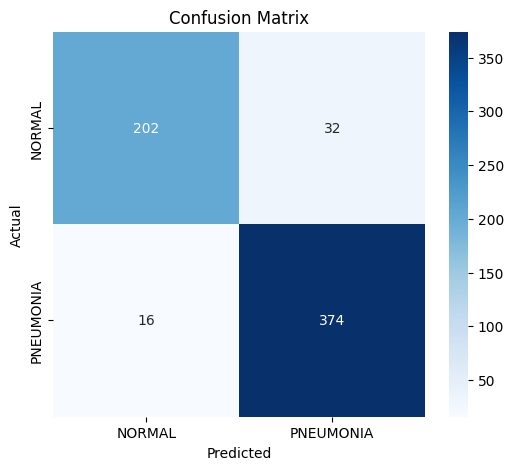

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['NORMAL','PNEUMONIA'],
            yticklabels=['NORMAL','PNEUMONIA'],
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## 10) Training Curves
Plotting accuracy and loss curves over epochs.


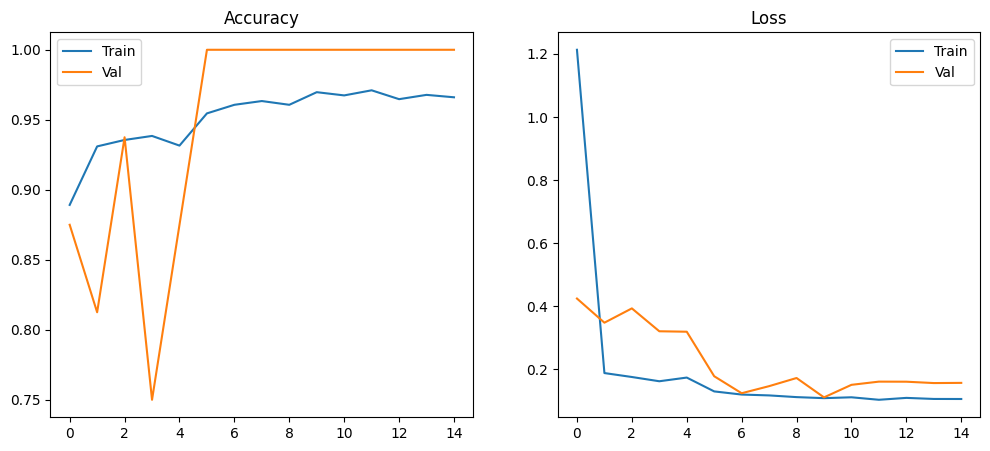

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()


## References (DenseNet121)

1. Kaggle Chest X-ray Pneumonia Dataset: [https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia](https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia)
2. DenseNet Original Paper: [https://arxiv.org/abs/1608.06993](https://arxiv.org/abs/1608.06993)
3. Keras DenseNet Documentation: [https://keras.io/api/applications/densenet/](https://keras.io/api/applications/densenet/)
4. TensorFlow Documentation: [https://www.tensorflow.org](https://www.tensorflow.org)
5. Similar GitHub Project: [https://github.com/BleeGleeWee/Chest-X-Ray-Pneumonia-Detection?utm_source=chatgpt.com](https://github.com/BleeGleeWee/Chest-X-Ray-Pneumonia-Detection?utm_source=chatgpt.com)
6. Pneumonia Detection Using Deep Learning (IRJET): [https://www.irjet.net/archives/V10/i11/IRJET-V10I1191.pdf](https://www.irjet.net/archives/V10/i11/IRJET-V10I1191.pdf)